In [ ]:
from google.colab import drive
import os

drive.mount("/content/drive")
DRIVE = "/content/drive/MyDrive"
PROJECT = f"{DRIVE}/abaya_bot_project"
os.makedirs(PROJECT, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q openpyxl pillow

In [ ]:
KB_PATH = f"{DRIVE}/store_info.txt"
CATALOG_PATH = f"{DRIVE}/abaya_catalog_template.xlsx"
IMAGES_DIR = f"{DRIVE}/img"
COLUMNS = {
    "code": "الكود (product_id)",
    "description": "الاسم/وصف قصير (name)",
    "price": "السعر (price)",
    "colors": "الألوان (colors)",
    "sizes": "المقاسات المتوفرة (sizes)",
    "fabric": "القماش (fabric)",
    "image": "ملف الصورة (photo_file)",
    "order type": "نوع الطلب (order_type)",
    "tailoring_days": "مدة التفصيل بالأيام (tailoring_days)",
    "stock": "التوفر (stock)"
}

In [ ]:
import shutil
shutil.copy(KB_PATH, f"{PROJECT}/store_info.md")
print(open(f"{PROJECT}/store_info.md", encoding="utf-8-sig").read())

**اسم المتجر:** ايرل  
**اسم البوت:** ايرال بوت  
**العملة:** الدينار البحريني (BHD)  
**اللغة:** اللهجة الخليجية البحرينية  
**خدمة العملاء:** البوت يرد 24 ساعة.

### معلومات المتجر
- المنتجات: عبايات جاهزة وتفصيل.
- الطلبات: عن طريق الإنستقرام والواتساب.
- نطاق الخدمة: البحرين ودول الخليج.

### المنتجات والكتالوج
- الكتالوج: يحتوي على كود واسم وقماش ولون وسعر كل عباية.
- الصور: لكل عباية صور مرتبطة بكودها في الكتالوج.
- التعرف على العباية: يطابق البوت صورة العميلة مع صور الكتالوج. إذا لم يتأكد من العباية، يحول المحادثة للموظفة.
- الألوان والأقمشة والأسعار: تؤخذ من الكتالوج فقط.
- العبايات الجاهزة: التوفر يعتمد على المخزون، والبوت لا يستطيع الاطلاع عليه. يجب التأكد من الموظفة.
- التفصيل: متاح للعبايات الموجودة في الكتالوج.

### المقاسات والتفصيل
- المقاسات: من 50 إلى 60، والمقاس يمثل طول العباية.
- العرض: ستاندر وثابت، ولكل طول قياسات محددة للعرض وطول اليد.
- العرض الخاص: متاح بالطلب في التفصيل بعد التأكد من الموظفة.
- معلومات التفصيل المطلوبة: طول العميلة فقط.
- مدة التفصيل: أسبوع أو

In [ ]:
import pandas as pd
df_check = pd.read_excel(
    CATALOG_PATH,
    sheet_name="Catalog",
    header=0
)

display(df_check.head(10))

,الكود (product_id),ملف الصورة (photo_file),الاسم/وصف قصير (name),القماش (fabric),الألوان (colors),السعر (price),المقاسات المتوفرة (sizes),نوع الطلب (order_type),مدة التفصيل بالأيام (tailoring_days),التوفر (stock)
0,EXAMPLE,IMG_0001.jpg,عباية سادة بأكمام واسعة,كريب,أسود، بني، كحلي,25,50-58,جاهزة وتفصيل,5,متوفر
1,AYL-095,AYL-095.jpg‏,عباية بقصة كلوش بقماش نقش الغزال قلبتين,شيفون,"اسود,بيج,بني",19,50-60,تفصيل,7,متوفر
2,AYL-094,AYL-094.jpg‏,عباية بقصة ستريت مع فتحات في الجوانب و زيج في ...,شيفون مخمل,"بنفسجي,تركوازي,بني,ماروني",27,50-60,تفصيل,7,متوفر
3,AYL-089,AYL-089.jpg‏,عباية بقصة البليزر الخفيف مع اسفنج في الاكتف,جاكار ياباني,اسود,19,50-60,تفصيل,7,متوفر
4,AYL-088,AYL-088.jpg‏,عباية بقصة ستريت مع دانتيل في الاطراف و من الد...,"مخمل كوري,شيفون",اسود,19,50-60,تفصيل,7,متوفر
5,AYL-091,AYL-091.jpg‏,عباية بقصه بليزر مع دانتيل,"مخمل كوري ,كريب","ماروني,اسود,كحلي",21,50-60,تفصيل,7,متوفر


In [ ]:
import io, json
from pathlib import Path
import openpyxl
from PIL import Image

def clean(v):
    if v is None:
        return ""
    if isinstance(v, float) and v.is_integer():
        v = int(v)
    return str(v).strip()

ws = openpyxl.load_workbook(CATALOG_PATH, data_only=True)["Catalog"]
headers = [clean(c.value) for c in ws[1]]
print("col:", headers)

missing = [v for k, v in COLUMNS.items() if k != "image" and v not in headers]
assert not missing, f"col not fund: {missing}"

embedded = {}
for im in getattr(ws, "_images", []):
    try:
        embedded[im.anchor._from.row + 1] = im._data()
    except Exception:
        pass

os.makedirs(f"{PROJECT}/images", exist_ok=True)
extra_cols = [h for h in headers if h and h not in COLUMNS.values()]
catalog = []

for r in range(2, ws.max_row + 1):
    vals = {h: clean(ws.cell(r, i + 1).value) for i, h in enumerate(headers) if h}
    if not any(vals.values()):
        continue
    row = {k: vals.get(v, "") for k, v in COLUMNS.items()}
    code = row["code"] or f"AB{r:03d}"

    data = embedded.get(r)
    if data is None:
        d = Path(IMAGES_DIR)
        image_name = row["image"].replace("\u200f", "").strip()
        cands = [d / Path(image_name).name] if image_name else []
        cands += [d / f"{code}.{e}" for e in ("jpg", "jpeg", "png", "webp")]
        for p in cands:
            if p.is_file():
                data = p.read_bytes()
                break
    if data is None:
        print(f"⚠️ skip row {r} ({code}): not fund img")
        continue

    Image.open(io.BytesIO(data)).convert("RGB").save(f"{PROJECT}/images/{code}.jpg", "JPEG", quality=90)
    extras = [f"{h}: {vals[h]}" for h in extra_cols if vals.get(h)]
    desc = " | ".join([x for x in [row["description"]] + extras if x])
    catalog.append({"code": code, "name": row["description"], "price": row["price"], "colors": row["colors"],
                    "sizes": row["sizes"], "description": desc, "image": f"{code}.jpg"})

json.dump(catalog, open(f"{PROJECT}/catalog.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)

col: ['الكود (product_id)', 'ملف الصورة (photo_file)', 'الاسم/وصف قصير (name)', 'القماش (fabric)', 'الألوان (colors)', 'السعر (price)', 'المقاسات المتوفرة (sizes)', 'نوع الطلب (order_type)', 'مدة التفصيل بالأيام (tailoring_days)', 'التوفر (stock)']
⚠️ skip row 2 (EXAMPLE): not fund img


Available Abayas:
AYL-095 - عباية بقصة كلوش بقماش نقش الغزال قلبتين
AYL-094 - عباية بقصة ستريت مع فتحات في الجوانب و زيج في الاطراف
AYL-089 - عباية بقصة البليزر الخفيف مع اسفنج في الاكتف
AYL-088 - عباية بقصة ستريت مع دانتيل في الاطراف و من الداخل شيفون
AYL-091 - عباية بقصه بليزر مع دانتيل
Enter abaya code: AYL-091
Name: عباية بقصه بليزر مع دانتيل
Price: 21 BHD
Colors: ماروني,اسود,كحلي
Sizes: 50-60


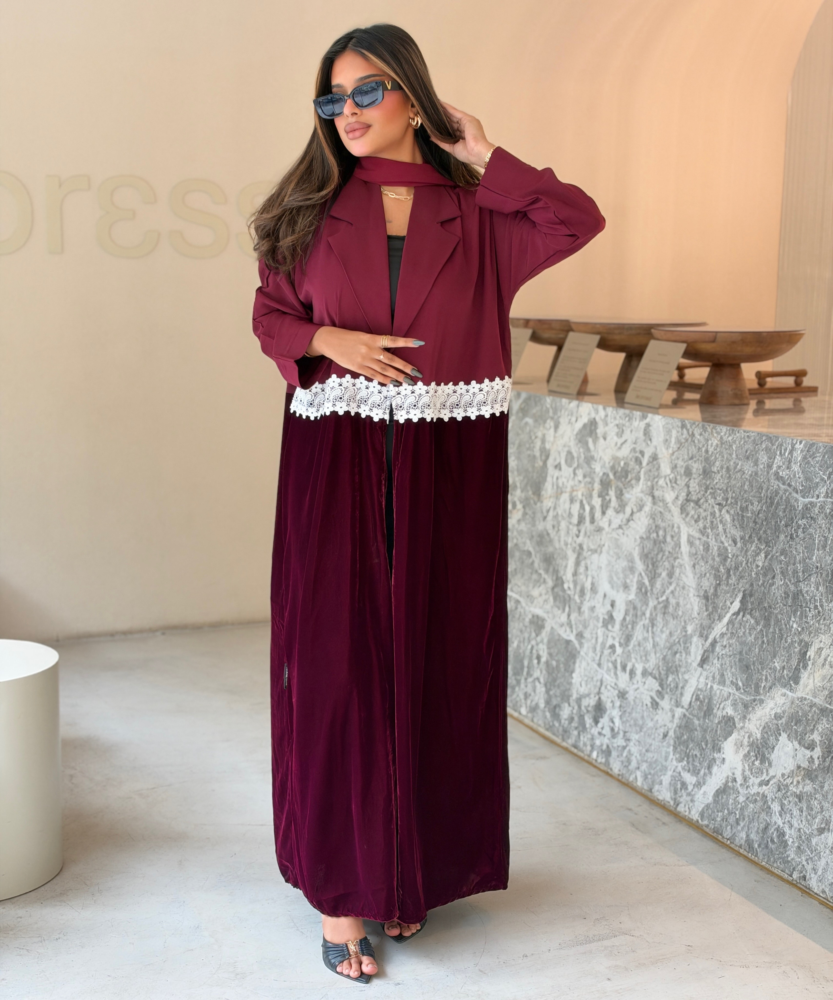

In [ ]:
import json
from IPython.display import display
from PIL import Image
from pathlib import Path

with open(f"{PROJECT}/catalog.json", "r", encoding="utf-8") as f:
    catalog = json.load(f)

print("Available Abayas:")

for item in catalog:
    print(item["code"], "-", item["name"])

selected_code = input("Enter abaya code: ").strip()

selected = next(
    (item for item in catalog if item["code"] == selected_code),
    None)

if selected:
    print("Name:", selected["name"])
    print("Price:", selected["price"], "BHD")
    print("Colors:", selected["colors"])
    print("Sizes:", selected["sizes"])

    image_path = Path(PROJECT) / "images" / selected["image"]

    display(Image.open(image_path))

else:
    print("Abaya not found!")